## Dự đoán điện ở bước kế tiếp — 10 phút
DS66B, nhóm 14: Trần Quang Huy, Bùi Ngọc Thuấn, Nguyễn Hoàng Thành.

52.416 dòng tại Tetouan, từ 01/01 đến 30/12/2017, cách nhau 10 phút, gồm ba khu vực.
Dùng số đo đã biết để dự đoán mức điện sau 10 phút. Một dòng X, ba đáp án y.

Mạch bài: xem dữ liệu → mốc đơn giản → mô hình với 8 số đo → thêm lịch sử → tuần/tháng → tìm tham số → học mức tăng/giảm → thử bỏ biến → tổng hợp.
Mỗi bước có điểm validation và test. Chọn đầu vào, tham số và mô hình bằng train/CV/validation; test chỉ để đối chiếu, không chọn theo test.
Test đã dùng ở các phiên trước, không phải tập kiểm chứng hoàn toàn mới. Các cấu hình và thứ tự thử được xác định trước khi chạy vòng này.


## 1. Công cụ


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
pd.options.display.float_format = '{:,.4f}'.format


## 2. Xem dữ liệu
Chia ngay sau đọc: 70% đầu train, 15% tiếp validation, 15% cuối test; không xáo trộn.
Hai ô dưới cùng hiện hai dòng đầu train: trước rồi sau đổi tên cột/định dạng giờ. Không sửa giá trị số đo.

### 2.1. Đọc, chia và xem dữ liệu thô


In [2]:
url = 'https://raw.githubusercontent.com/huy1907ddddddd/DS66B_group_14/eaabc962460c76dc76db4a59d3de5a5dfd6329fd/data/raw/Tetuan%20City%20power%20consumption.csv'
data = pd.read_csv(url)
train_end = int(len(data) * 0.70)
test_start = int(len(data) * 0.85)
test = data.iloc[test_start:].copy()
df = data.iloc[:test_start].copy()
del data
display(df.iloc[:train_end].head(2))


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,1/1/2017 0:10,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### 2.2. Đổi tên cột và định dạng giờ
Tên ngắn giúp viết code dễ hơn. Chuyển chuỗi ngày giờ thành thời điểm để tính khoảng cách, lấy giờ/thứ/tháng.


In [3]:
weather = ['temperature', 'humidity', 'wind_speed', 'general_diffuse', 'diffuse']
zones = ['zone_1', 'zone_2', 'zone_3']
df.columns = ['time'] + weather + zones
df['time'] = pd.to_datetime(df['time'], format='%m/%d/%Y %H:%M')
display(df.iloc[:train_end].head(2))


,time,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3
0,2017-01-01 00:00:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,2017-01-01 00:10:00,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### Xem mức điện của train theo thời gian

Ba đường tương ứng ba khu vực. Mỗi điểm là mức điện trung bình một ngày, giúp nhìn rõ xu hướng trong gần chín tháng train. Đây là trung bình các số đo, không phải tổng điện năng trong ngày. Chỉ biểu đồ được gom theo ngày; dữ liệu học vẫn cách nhau 10 phút. Không dùng validation hoặc test để vẽ.


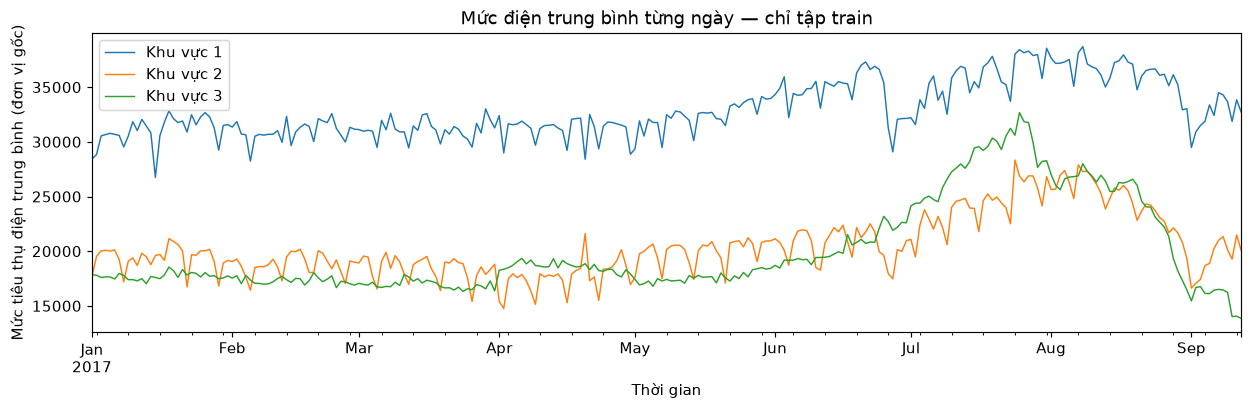

In [4]:
train_view = df.iloc[:train_end]
daily_power = train_view.set_index('time')[zones].resample('D').mean()
daily_power.plot(figsize=(12, 4), linewidth=1)
plt.title('Mức điện trung bình từng ngày — chỉ tập train')
plt.xlabel('Thời gian')
plt.ylabel('Mức tiêu thụ điện trung bình (đơn vị gốc)')
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])
plt.tight_layout()
plt.show()


### EDA — Kiểm tra và xem dữ liệu train
Kiểm tra dữ liệu trước, sau đó mỗi ô code hiện một bảng riêng để dễ đọc. Các bảng thống kê chỉ dùng train.


In [ ]:
assert df.notna().all().all() and np.isfinite(df[weather + zones]).all().all()
assert not df.time.duplicated().any()
assert df.time.diff().dropna().eq(pd.Timedelta(minutes=10)).all()


### Thống kê chung của train


In [ ]:
early = df.iloc[:train_end]
display(early[weather + zones].describe().T)


,count,mean,std,min,25%,50%,75%,max
temperature,"36,691.0000",19.2393,6.1815,3.2470,14.3400,19.1600,24.0400,40.0100
humidity,"36,691.0000",67.6561,16.0826,11.3400,57.3800,69.5200,81.4000,93.6000
wind_speed,"36,691.0000",1.9980,2.3575,0.0500,0.0770,0.0860,4.9130,4.9780
general_diffuse,"36,691.0000",207.6599,285.7269,0.0040,0.0660,18.2100,383.2000,"1,163.0000"
diffuse,"36,691.0000",86.5442,135.8819,0.0190,0.1260,16.4400,119.8000,936.0000
zone_1,"36,691.0000","32,956.8892","7,255.5949","13,895.6962","26,703.4233","33,089.3617","38,195.8804","52,204.3951"
zone_2,"36,691.0000","20,444.8429","5,067.7250","8,560.0815","16,298.7573","20,444.3506","23,875.6239","37,408.8608"
zone_3,"36,691.0000","20,024.4123","6,464.3840","8,189.9081","15,290.1818","18,071.6308","24,821.5674","47,598.3264"


### Mức điện trung bình theo giờ


In [ ]:
display(early.groupby(early.time.dt.hour)[zones].mean().rename_axis('Giờ'))


,zone_1,zone_2,zone_3
Giờ,,,
0,"31,465.5519","19,709.0726","21,259.3980"
1,"28,591.8702","17,776.2778","19,267.7101"
2,"27,274.3903","16,743.7338","18,082.1775"
3,"26,133.7303","15,965.9318","17,116.5272"
4,"25,093.5248","15,306.0989","16,281.1984"
5,"23,194.7931","14,107.9265","14,268.2972"
6,"23,203.7973","14,183.5947","13,215.6828"
7,"24,285.3210","15,245.8299","13,095.7376"
8,"26,891.5697","17,091.8244","14,378.4492"


### Mức điện trung bình theo thứ


In [ ]:
display(early.groupby(early.time.dt.dayofweek)[zones].mean().rename_axis('Thứ: 0 = thứ Hai'))


,zone_1,zone_2,zone_3
Thứ: 0 = thứ Hai,,,
0,"33,187.0370","20,737.7564","19,903.2447"
1,"33,209.7260","20,893.8191","19,945.2474"
2,"33,437.3696","20,974.1974","20,063.5439"
3,"33,468.5365","21,176.9508","20,102.8077"
4,"33,067.0187","20,897.2381","19,730.3626"
5,"33,056.3388","19,921.4258","20,324.5895"
6,"31,306.0521","18,547.1306","20,104.0014"


### Mức điện trung bình theo tháng


In [ ]:
display(early.groupby(early.time.dt.month)[zones].mean().rename_axis('Tháng'))


,zone_1,zone_2,zone_3
Tháng,,,
1,"31,032.4935","19,394.4447","17,746.0953"
2,"30,985.7536","18,787.7931","17,335.0022"
3,"31,155.1654","18,457.9375","16,947.6860"
4,"31,169.7682","17,633.9664","18,593.1677"
5,"32,396.0092","19,977.2879","17,621.1010"
6,"34,605.5408","20,670.9286","20,430.9415"
7,"35,831.5536","24,147.8869","28,194.1112"
8,"36,435.1896","24,656.2166","24,648.8947"
9,"32,558.6170","19,363.7656","15,781.0580"


## 3. Cách làm ban đầu — chỉ 8 số đo hiện tại
X gồm 5 số đo thời tiết/bức xạ và điện hiện tại của 3 khu vực. y là điện ba khu vực sau 10 phút.
Chưa thêm lag, trung bình hay sin/cos. Giữ cố định các thời điểm đánh giá từ lúc đáp án đủ một tháng lịch sử, vì phần sau sẽ thử lịch sử tháng.
Đây là cách giữ cùng đề kiểm tra cho mọi bước; không chọn thời điểm dựa trên số điện hoặc sai số.


In [6]:
horizon = 1
time_step = df.time.diff().dropna().mode().iloc[0]
steps_per_day = int(pd.Timedelta(days=1) / time_step)
raw_columns = weather + zones
evaluation_start = df.time.iloc[0] + pd.DateOffset(months=1)
target_time = df.time + horizon * time_step
y = df[zones].shift(-horizon)
valid = (target_time >= evaluation_start) & y.notna().all(axis=1)
X, y = df.loc[valid, raw_columns], y.loc[valid]
origin, target_time = df.time.loc[valid], target_time.loc[valid]
validation_start = df.time.iloc[train_end]
train = target_time < validation_start
validation = origin >= validation_start
X_train_all, y_train = X.loc[train], y.loc[train]
X_val_all, y_val = X.loc[validation], y.loc[validation]
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)
print('Train:', len(y_train), '| Validation:', len(y_val))
assert target_time[train].max() < origin[validation].min()


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Train: 32227 | Validation: 7861


### Chuẩn bị test để đối chiếu từng bước
Chỉ tạo đầu vào và đáp án để chấm; không fit mô hình, scaler hay PCA bằng test.
Đánh giá cuốn chiếu: lúc dự đoán đã biết số đo hiện tại, chưa biết dòng tiếp theo.


In [7]:
test.columns = df.columns
test['time'] = pd.to_datetime(test['time'], format='%m/%d/%Y %H:%M')
assert test.time.diff().dropna().eq(time_step).all()
assert test.time.iloc[0] - df.time.iloc[-1] == time_step
assert test.notna().all().all() and np.isfinite(test[weather + zones]).all().all()
X_test_all = test[raw_columns].iloc[:-horizon].copy()
y_test = test[zones].shift(-horizon).iloc[:-horizon]
test_origin = test.time.iloc[:-horizon]
test_target_time = test_origin + horizon * time_step
assert target_time[validation].max() < test_origin.min()
print('Số dòng test được chấm:', len(y_test))


Số dòng test được chấm: 7862


### Cách chấm dùng chung
MAE là độ lệch trung bình, càng nhỏ càng tốt. RMSE nhấn mạnh lỗi lớn; MAPE là phần trăm sai số; R² không phải phần trăm chính xác.
MAE/RMSE/MAPE tính chung ba khu vực, R² trung bình điểm từng khu vực. Hai hàm dưới giúp các bước chấm và hiện bảng theo cùng một cách.


In [8]:
def metrics(truth, predicted):
    return [mean_absolute_error(truth, predicted),
            np.sqrt(mean_squared_error(truth, predicted)),
            mean_absolute_percentage_error(truth, predicted) * 100,
            r2_score(truth, predicted)]

metric_names = ['MAE', 'RMSE', 'MAPE (%)', 'R2']

result_rows, step_tables = [], []
val_predictions, train_predictions, test_predictions = {}, {}, {}
candidates, candidate_columns = {}, {}
extra_models, extra_columns, delta_names = {}, {}, set()
result_columns = ['Model', 'Số biến'] + ['Validation ' + m for m in metric_names]
result_columns += ['Train ' + m for m in metric_names] + ['Test ' + m for m in metric_names]

def record_result(name, val_pred, train_pred, test_pred, count, eligible=True):
    if eligible:
        val_predictions[name] = val_pred
    train_predictions[name], test_predictions[name] = train_pred, test_pred
    result_rows.append([name, count, *metrics(y_val, val_pred), *metrics(y_train, train_pred), *metrics(y_test, test_pred)])

def compare_step(step, names, reference):
    results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')
    table = results.loc[names].copy()
    table['Giảm Test MAE so với Persistence'] = results.loc['Persistence', 'Test MAE'] - table['Test MAE']
    table['Giảm Test MAE so với ' + reference] = results.loc[reference, 'Test MAE'] - table['Test MAE']
    display(table.drop(columns=[c for c in table if c.startswith('Train ') or c in ['Validation RMSE', 'Validation MAPE (%)', 'Validation R2']]))
    step_tables.append(table.reset_index().assign(Bước=step))


### Mốc đơn giản nhất: điện 10 phút tới bằng điện hiện tại
Ví dụ hiện tại là 30.000 thì đoán 10 phút sau cũng là 30.000. Chưa cần mô hình học.
Mô hình phải vượt được mốc thực tế này thì việc học mới có ích.


In [9]:
record_result('Persistence', X_val_all[zones].to_numpy(), X_train_all[zones].to_numpy(), X_test_all[zones].to_numpy(), 3)
compare_step('Mốc giữ nguyên', ['Persistence'], 'Persistence')


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000


## 4. Mô hình ban đầu — cùng 8 đầu vào
Linear học công thức cộng có trọng số; Ridge/Lasso thêm mức phạt; KNN tìm mẫu gần; cây chia điều kiện; rừng gộp nhiều cây.
PCA + Ridge thử nén đầu vào; MLP là mạng nơ-ron nhỏ. Chưa tìm tham số, chưa thêm lịch sử.
Chuẩn hóa/PCA chỉ học trên train; MLP chuẩn hóa cả đầu vào và đáp án.


In [10]:
models = {
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=100)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=200000, tol=0.001, precompute=True)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights='distance', n_jobs=2)),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5, random_state=42, n_jobs=2),
    'PCA + Ridge': make_pipeline(StandardScaler(), PCA(n_components=0.95), Ridge(alpha=1)),
    'MLP': TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(32, 16), alpha=0.001, max_iter=500, tol=0.00001,
            n_iter_no_change=30, shuffle=False, early_stopping=False, random_state=42)),
        transformer=StandardScaler())
}


In [11]:
simple_models = {}
for name, template in models.items():
    model = clone(template)
    model.fit(X_train_all[raw_columns], y_train)
    label = name + ' (8 biến)'
    simple_models[label] = model
    candidates[label], candidate_columns[label] = model, raw_columns
    record_result(label, model.predict(X_val_all[raw_columns]), model.predict(X_train_all[raw_columns]), model.predict(X_test_all[raw_columns]), 8)
compare_step('Mô hình ban đầu', ['Persistence'] + list(simple_models), 'Persistence')


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456
Ridge (8 biến),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338
Lasso (8 biến),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166
KNN (8 biến),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154"
Decision Tree (8 biến),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011"
Random Forest (8 biến),8,874.3131,"1,919.6764","2,657.0037",11.1873,0.6820,"-1,626.5634"
PCA + Ridge (8 biến),8,"3,357.4102","4,131.2015","4,708.7962",24.2279,-0.2729,"-3,838.0885"
MLP (8 biến),8,454.2918,754.6490,"1,074.7358",4.1437,0.9377,-461.5360


## 5. Tối ưu 1 — thêm quá khứ và giờ trong ngày
Chỉ biết số hiện tại có thể chưa biết điện đang tăng hay giảm. Thêm các số điện trước đó, trung bình và độ dao động gần đây.
Hàm dưới chuẩn bị cả nhóm tuần/tháng để bước sau dùng; bước này chỉ cho Linear dùng nhóm ngắn hạn 40 biến.

Vì sao có sin/cos? 23 giờ và 0 giờ thực tế chỉ cách một giờ, nhưng hai con số lại chênh 23. Đặt thời gian lên mặt đồng hồ tròn để cuối ngày nối với đầu ngày.
Hai tọa độ sin/cos mô tả vị trí trên vòng tròn; dùng một tọa độ có thể làm hai thời điểm khác nhau trùng nhau. Thứ trong tuần cũng là vòng tròn.
Đây là cách mã hóa chu kỳ thông dụng, không bảo đảm mọi mô hình đều tăng điểm. Chưa có thử nghiệm riêng để quy toàn bộ mức cải thiện cho sin/cos.


In [12]:
def make_features(frame):
    future_time = frame.time + horizon * time_step
    X = frame[weather + zones].copy()
    for zone in zones:
        for lag in [1, 3, 6, 18, steps_per_day]:
            X[f'{zone}_lag_{lag}'] = frame[zone].shift(lag)
        for window in [6, 18]:
            X[f'{zone}_mean_{window}'] = frame[zone].rolling(window).mean()
            X[f'{zone}_std_{window}'] = frame[zone].rolling(window).std()
        X[f'{zone}_daily_reference'] = frame[zone].shift(steps_per_day - horizon)
        X[f'{zone}_weekly_lag'] = frame[zone].shift(7 * steps_per_day)
        X[f'{zone}_weekly_reference'] = frame[zone].shift(7 * steps_per_day - horizon)
        previous_month = future_time - pd.DateOffset(months=1)
        X[f'{zone}_monthly_reference'] = previous_month.map(frame.set_index('time')[zone])
    minute = future_time.dt.hour * 60 + future_time.dt.minute
    X['clock_sin'] = np.sin(2 * np.pi * minute / 1440)
    X['clock_cos'] = np.cos(2 * np.pi * minute / 1440)
    X['weekday_sin'] = np.sin(2 * np.pi * future_time.dt.dayofweek / 7)
    X['weekday_cos'] = np.cos(2 * np.pi * future_time.dt.dayofweek / 7)
    X['is_weekend'] = (future_time.dt.dayofweek >= 5).astype(float)
    X['month_sin'] = np.sin(2 * np.pi * (future_time.dt.month - 1) / 12)
    X['month_cos'] = np.cos(2 * np.pi * (future_time.dt.month - 1) / 12)
    phase = (future_time.dt.day - 1) / future_time.dt.days_in_month
    X['month_day_sin'] = np.sin(2 * np.pi * phase)
    X['month_day_cos'] = np.cos(2 * np.pi * phase)
    y = frame[zones].shift(-horizon)
    valid = X.notna().all(axis=1) & y.notna().all(axis=1)
    return X.loc[valid], y.loc[valid], frame.time.loc[valid], future_time.loc[valid]

X, y, origin, target_time = make_features(df)
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)
print('Số đầu vào khi có cả tuần và tháng:', X.shape[1])
display(X.head(2))


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Số đầu vào khi có cả tuần và tháng: 56


,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3,zone_1_lag_1,zone_1_lag_3,zone_1_lag_6,zone_1_lag_18,zone_1_lag_144,zone_1_mean_6,zone_1_std_6,zone_1_mean_18,zone_1_std_18,zone_1_daily_reference,zone_1_weekly_lag,zone_1_weekly_reference,zone_1_monthly_reference,zone_2_lag_1,zone_2_lag_3,zone_2_lag_6,zone_2_lag_18,zone_2_lag_144,zone_2_mean_6,zone_2_std_6,zone_2_mean_18,zone_2_std_18,zone_2_daily_reference,zone_2_weekly_lag,zone_2_weekly_reference,zone_2_monthly_reference,zone_3_lag_1,zone_3_lag_3,zone_3_lag_6,zone_3_lag_18,zone_3_lag_144,zone_3_mean_6,zone_3_std_6,zone_3_mean_18,zone_3_std_18,zone_3_daily_reference,zone_3_weekly_lag,zone_3_weekly_reference,zone_3_monthly_reference,clock_sin,clock_cos,weekday_sin,weekday_cos,is_weekend,month_sin,month_cos,month_day_sin,month_day_cos
4463,11.4700,69.6300,4.9210,0.0480,0.1520,"31,084.5570","19,225.5319","19,477.5904","31,837.9747","33,685.0633","36,218.7342","42,756.4557","31,376.2025","33,158.4810","1,577.0087","37,590.5485","3,726.8185","30,270.3798","30,379.7468","29,778.2278","34,055.6962","19,728.8754","20,768.3891","22,300.3040","25,400.6079","19,203.6474","20,456.5350",927.8234,"23,117.9331","2,163.6102","18,579.9392","19,641.3374","19,141.6413","16,128.8754","19,980.7229","20,929.1566","22,716.1446","25,896.8675","19,396.6265","20,732.5301",946.8314,"23,398.8755","2,167.6630","18,644.8193","19,020.7229","18,639.0361","20,240.9639",0.0000,1.0000,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000
4464,11.5700,66.2600,4.9150,0.0590,0.1190,"29,892.2034","18,729.4833","18,848.8040","31,084.5570","32,688.6076","35,228.3544","42,373.6709","30,270.3798","32,269.1225","1,677.6904","36,897.1337","3,939.5985","29,638.4810","29,778.2278","28,806.0759","29,814.6835","19,225.5319","20,122.7964","21,658.3587","25,462.6140","18,579.9392","19,968.3891",939.4563,"22,743.8703","2,311.3901","18,237.0821","19,141.6413","18,561.7021","19,375.0760","19,477.5904","20,506.9879","22,051.0843","25,798.5542","18,644.8193","20,198.8167",957.4119,"23,012.7783","2,328.0941","18,361.4458","18,639.0361","18,234.2169","20,131.0843",0.0436,0.9990,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000


In [13]:
old_train_index, old_val_index, old_test_index = X_train_all.index, X_val_all.index, X_test_all.index
validation_start = df.time.iloc[train_end]
train, validation = target_time < validation_start, origin >= validation_start
X_train_all, y_train = X.loc[train], y.loc[train]
X_val_all, y_val = X.loc[validation], y.loc[validation]
test_history = pd.concat([df.tail(32 * steps_per_day), test])
X_test_all, y_test, test_origin, test_target_time = make_features(test_history)
in_test = test_origin >= test.time.iloc[0]
X_test_all, y_test = X_test_all.loc[in_test], y_test.loc[in_test]
test_origin, test_target_time = test_origin.loc[in_test], test_target_time.loc[in_test]
assert X_train_all.index.equals(old_train_index) and X_val_all.index.equals(old_val_index)
assert X_test_all.index.equals(old_test_index)
weekly = [c for c in X if 'weekly_' in c or c.startswith('weekday_') or c == 'is_weekend']
monthly = [c for c in X if 'monthly_' in c or c.startswith('month_')]
short = [c for c in X if c not in weekly + monthly]
short_model = make_pipeline(StandardScaler(), LinearRegression())
short_model.fit(X_train_all[short], y_train)
candidates['Linear (40 biến)'], candidate_columns['Linear (40 biến)'] = short_model, short
record_result('Linear (40 biến)', short_model.predict(X_val_all[short]), short_model.predict(X_train_all[short]), short_model.predict(X_test_all[short]), len(short))
compare_step('Thêm quá khứ và giờ', ['Persistence', 'Linear (8 biến)', 'Linear (40 biến)'], 'Linear (8 biến)')


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (8 biến)
Model,,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000,8.4456
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Linear (40 biến),40,166.4142,178.6915,278.4380,0.9275,0.9965,114.4215,122.8672


## 6. Tối ưu 2 — thêm lặp lại theo tuần và tháng
Điện cùng giờ tuần trước có thể gợi ý thói quen lặp lại. Tháng trước có thể giúp hoặc làm nhiễu, nên phải thử.
Giữ cùng Linear và cùng thời điểm, chỉ thay nhóm đầu vào. Chọn nhóm bằng validation trước khi hiện điểm test.
Tháng dùng DateOffset theo lịch; ngày không tồn tại được lùi về ngày cuối tháng trước, không coi mọi tháng đều có 30 ngày.


In [14]:
feature_sets = {'Ngắn hạn': short, '+ Tuần': short + weekly, '+ Tháng': short + monthly, '+ Tuần và tháng': list(X.columns)}
season_rows, season_models = [], {}
for name, columns in feature_sets.items():
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(X_train_all[columns], y_train)
    error = mean_absolute_error(y_val, model.predict(X_val_all[columns]))
    season_models[name] = model
    season_rows.append([name, len(columns), error])
seasonality = pd.DataFrame(season_rows, columns=['Nhóm đầu vào', 'Số biến', 'Validation MAE'])
selected_group = seasonality.loc[seasonality['Validation MAE'].idxmin(), 'Nhóm đầu vào']
selected_columns = feature_sets[selected_group]
X_train, X_val = X_train_all[selected_columns], X_val_all[selected_columns]
X_test = X_test_all[selected_columns]
for name, model in season_models.items():
    columns = feature_sets[name]
    record_result('Linear - ' + name, model.predict(X_val_all[columns]), model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns), eligible=False)
display(seasonality)
print('Nhóm được chọn bằng validation:', selected_group)
compare_step('Thêm tuần và tháng', ['Linear - ' + name for name in feature_sets], 'Linear (40 biến)')


Nhóm được chọn bằng validation: + Tuần


,Nhóm đầu vào,Số biến,Validation MAE
0,Ngắn hạn,40,166.4142
1,+ Tuần,49,163.7002
2,+ Tháng,47,168.1104
3,+ Tuần và tháng,56,165.4323


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (40 biến)
Model,,,,,,,,
Linear - Ngắn hạn,40,166.4142,178.6915,278.4380,0.9275,0.9965,114.4215,0.0000
Linear - + Tuần,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,5.1606
Linear - + Tháng,47,168.1104,181.8413,281.0263,0.9499,0.9964,111.2717,-3.1499
Linear - + Tuần và tháng,56,165.4323,176.7311,273.6721,0.9226,0.9966,116.3819,1.9604


### Áp dụng nhóm đầu vào đã chọn cho các mô hình
Tham số vẫn như lúc đầu; lần này chỉ đổi đầu vào. Giữ các bản 8 biến để so lại.
Thêm ba mốc đoán bằng cùng giờ hôm qua, tuần trước, tháng trước. Đây là mốc đối chiếu, không phải mô hình huấn luyện.


In [15]:
baseline_columns = {
    'Persistence': zones,
    'Previous day': [f'{z}_daily_reference' for z in zones],
    'Previous week': [f'{z}_weekly_reference' for z in zones],
    'Previous month': [f'{z}_monthly_reference' for z in zones]
}


for name, columns in baseline_columns.items():
    if name != 'Persistence':
        record_result(name, X_val_all[columns].to_numpy(), X_train_all[columns].to_numpy(), X_test_all[columns].to_numpy(), len(columns))
for name, model in models.items():
    model.fit(X_train, y_train)
    candidates[name], candidate_columns[name] = model, selected_columns
    record_result(name, model.predict(X_val), model.predict(X_train), model.predict(X_test), len(selected_columns))
initial_results = pd.DataFrame([[name, *metrics(y_val, val_predictions[name])] for name in models], columns=['Model'] + metric_names).set_index('Model')
compare_step('Áp dụng đầu vào cho các mô hình', list(simple_models) + list(models), 'Linear (8 biến)')


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (8 biến)
Model,,,,,,,,
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Ridge (8 biến),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338,-55.8882
Lasso (8 biến),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166,0.3290
KNN (8 biến),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154","-2,567.5697"
Decision Tree (8 biến),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011","-1,922.4555"
Random Forest (8 biến),8,874.3131,"1,919.6764","2,657.0037",11.1873,0.6820,"-1,626.5634","-1,618.1178"
PCA + Ridge (8 biến),8,"3,357.4102","4,131.2015","4,708.7962",24.2279,-0.2729,"-3,838.0885","-3,829.6428"
MLP (8 biến),8,454.2918,754.6490,"1,074.7358",4.1437,0.9377,-461.5360,-453.0904
Linear,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,128.0277


## 7. Tối ưu 3 — tìm tham số
Giữ đầu vào, thử cấu hình bằng ba lượt CV theo thời gian trong train, chừa một dòng ở ranh giới.
Chọn tham số theo CV MAE; sau mỗi nhóm hiện điểm trước/sau trên validation và test. Không chỉnh tham số dựa vào test.
Danh sách cấu hình hữu hạn, không gọi là tối ưu tuyệt đối. Bản tìm tham số có thể kém hơn bản đầu trên validation/test.


In [16]:
cv = TimeSeriesSplit(n_splits=3, gap=horizon)
tuned, searches, tuning_rows = {}, {}, []

def tune_model(name, grid):
    search = GridSearchCV(models[name], grid, scoring='neg_mean_absolute_error', cv=cv, n_jobs=1, error_score='raise')
    search.fit(X_train, y_train)
    model = search.best_estimator_
    tuned[name], searches[name] = model, search
    label = name + ' (tuned)'
    candidates[label], candidate_columns[label] = model, selected_columns
    val_pred = model.predict(X_val)
    record_result(label, val_pred, model.predict(X_train), model.predict(X_test), len(selected_columns))
    tuning_rows.append([name, search.best_params_, -search.best_score_, mean_absolute_error(y_val, val_pred)])
    print(name, '| Tham số:', search.best_params_, '| CV MAE:', -search.best_score_)
    compare_step('Tìm tham số - ' + name, [name, label], name)


### Ridge và Lasso
Tên ridge__alpha nghĩa là chỉnh Alpha của bước Ridge bên trong pipeline. Lasso dùng tương tự.


In [17]:
tune_model('Ridge', {'ridge__alpha': [0.001, 0.1, 1, 10, 100, 1000]})
tune_model('Lasso', {'lasso__alpha': [0.1, 1, 10, 100]})


Ridge | Tham số: {'ridge__alpha': 0.001} | CV MAE: 185.91970627292997
Lasso | Tham số: {'lasso__alpha': 0.1} | CV MAE: 195.98277660023032


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Ridge
Model,,,,,,,,
Ridge,49,210.9964,255.5105,366.1971,1.3066,0.9940,37.6025,0.0000
Ridge (tuned),49,163.7004,173.5318,271.3373,0.8951,0.9967,119.5812,81.9787


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Lasso
Model,,,,,,,,
Lasso,49,223.5357,277.6832,391.2877,1.3941,0.9937,15.4298,0.0000
Lasso (tuned),49,183.3297,196.1033,299.8879,1.0700,0.9953,97.0097,81.5799


### KNN và đồ thị K
Chọn K bằng MAE nhỏ nhất trên CV. Đường cong để nhìn xu hướng, không đoán K bằng mắt.


KNN | Tham số: {'kneighborsregressor__n_neighbors': 15} | CV MAE: 1419.2993052958889


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với KNN
Model,,,,,,,,
KNN,49,"1,837.1900","3,213.8866","3,646.0513",18.8797,0.2541,"-2,920.7736",0.0000
KNN (tuned),49,"1,837.1900","3,213.8866","3,646.0513",18.8797,0.2541,"-2,920.7736",0.0000


,K,CV MAE
0,3,"1,454.4968"
1,5,"1,435.7933"
2,9,"1,423.4688"
3,15,"1,419.2993"
4,21,"1,420.5890"
5,31,"1,424.9274"


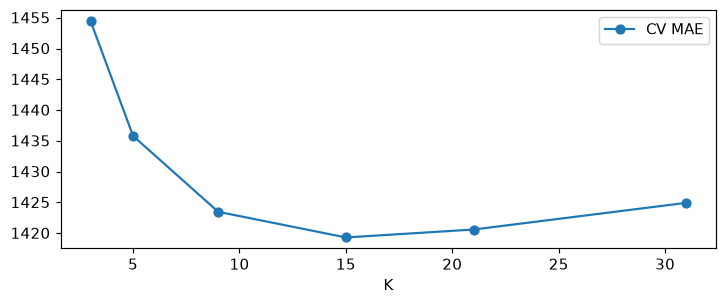

In [18]:
tune_model('KNN', {'kneighborsregressor__n_neighbors': [3, 5, 9, 15, 21, 31]})
search = searches['KNN']
k_scores = pd.DataFrame({'K': search.cv_results_['param_kneighborsregressor__n_neighbors'],
                         'CV MAE': -search.cv_results_['mean_test_score']})
display(k_scores)
k_scores.plot(x='K', y='CV MAE', marker='o', figsize=(7, 3))
plt.tight_layout()
plt.show()


### Cây và rừng
Chạy tìm tham số cho cả hai. Rừng giữ 60 cây để thời gian chạy vừa phải.


In [19]:
tune_model('Decision Tree', {'max_depth': [6, 12, 18, None], 'min_samples_leaf': [5, 20]})
tune_model('Random Forest', {'max_depth': [10, 18, None], 'min_samples_leaf': [2, 10]})


Decision Tree | Tham số: {'max_depth': None, 'min_samples_leaf': 5} | CV MAE: 1003.3244853515747
Random Forest | Tham số: {'max_depth': 18, 'min_samples_leaf': 2} | CV MAE: 769.884644123943


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Decision Tree
Model,,,,,,,,
Decision Tree,49,"1,118.3675","2,176.6558","3,067.6209",12.4191,0.5937,"-1,883.5428",0.0000
Decision Tree (tuned),49,"1,013.9816","2,045.0757","2,952.3067",11.0290,0.6517,"-1,751.9628",131.5800


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Random Forest
Model,,,,,,,,
Random Forest,49,942.4652,"1,956.8568","2,818.7840",11.0688,0.6654,"-1,663.7438",0.0000
Random Forest (tuned),49,910.6617,"1,878.9355","2,739.3874",10.4515,0.6910,"-1,585.8225",77.9213


### PCA và MLP
PCA và bộ chuẩn hóa được học lại trong mỗi lượt CV.
Với MLP, regressor__mlpregressor đi vào mạng bên trong bộ chuẩn hóa đáp án; hidden_layer_sizes là số nút ở từng lớp ẩn.
MLP không dùng early stopping với phép chia ngẫu nhiên. Shuffle=False giữ thứ tự các mẫu khi học.


In [20]:
tune_model('PCA + Ridge', {'pca__n_components': [0.90, 0.95, 0.99, 0.999], 'ridge__alpha': [0.1, 10]})
tune_model('MLP', {'regressor__mlpregressor__hidden_layer_sizes': [(32,), (32, 16)],
                   'regressor__mlpregressor__alpha': [0.001, 0.1]})
tuning_results = pd.DataFrame(tuning_rows, columns=['Model', 'Tham số chọn', 'CV MAE', 'Validation MAE'])
display(tuning_results)


PCA + Ridge | Tham số: {'pca__n_components': 0.999, 'ridge__alpha': 0.1} | CV MAE: 361.2396517242064
MLP | Tham số: {'regressor__mlpregressor__alpha': 0.1, 'regressor__mlpregressor__hidden_layer_sizes': (32, 16)} | CV MAE: 341.98977173672296


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với PCA + Ridge
Model,,,,,,,,
PCA + Ridge,49,760.0683,"1,111.9870","1,391.1437",5.6129,0.9192,-818.8740,0.0000
PCA + Ridge (tuned),49,290.6022,348.7596,486.7430,1.8085,0.9891,-55.6466,763.2274


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với MLP
Model,,,,,,,,
MLP,49,301.7883,536.4603,725.9228,2.6921,0.9783,-243.3473,0.0000
MLP (tuned),49,413.6242,865.7364,"1,073.5361",5.5248,0.9343,-572.6234,-329.2761


,Model,Tham số chọn,CV MAE,Validation MAE
0,Ridge,{'ridge__alpha': 0.001},185.9197,163.7004
1,Lasso,{'lasso__alpha': 0.1},195.9828,183.3297
2,KNN,{'kneighborsregressor__n_neighbors': 15},"1,419.2993","1,837.1900"
3,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 5}","1,003.3245","1,013.9816"
4,Random Forest,"{'max_depth': 18, 'min_samples_leaf': 2}",769.8846,910.6617
5,PCA + Ridge,"{'pca__n_components': 0.999, 'ridge__alpha': 0.1}",361.2397,290.6022
6,MLP,"{'regressor__mlpregressor__alpha': 0.1, 'regre...",341.9898,413.6242


## 8. Tối ưu 4 — học mức tăng/giảm
Thay vì hỏi điện sắp tới là bao nhiêu, hỏi điện sẽ tăng/giảm bao nhiêu so với hiện tại. Dự đoán xong cộng lại mức hiện tại.
Thử với RF/MLP đã tìm tham số; giữ nguyên tham số để chỉ đo tác động đổi đáp án. Chưa tìm tham số riêng cho delta.
Clone học lại cả bộ chuẩn hóa đáp án, không dùng thang đo cũ. Không cắt mức giảm âm.


In [21]:
delta_train = y_train.to_numpy() - X_train_all[zones].to_numpy()
delta_names, delta_rows = set(), []
for name in ['Random Forest', 'MLP']:
    model = clone(tuned[name])
    cv_errors = -cross_val_score(model, X_train, delta_train, scoring='neg_mean_absolute_error',
                                 cv=cv, n_jobs=1, error_score='raise')
    model.fit(X_train, delta_train)
    label = name + ' (delta)'
    predicted = X_val_all[zones].to_numpy() + model.predict(X_val)
    extra_models[label], extra_columns[label] = model, selected_columns
    delta_names.add(label)
    val_predictions[label] = predicted
    before_mae = mean_absolute_error(y_val, val_predictions[name + ' (tuned)'])
    candidates[label], candidate_columns[label] = model, selected_columns
    record_result(label, predicted, X_train_all[zones].to_numpy() + model.predict(X_train), X_test_all[zones].to_numpy() + model.predict(X_test), len(selected_columns))
    compare_step('Học mức tăng/giảm - ' + name, [name + ' (tuned)', label], name + ' (tuned)')
    delta_rows.append([label, before_mae, cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])
delta_results = pd.DataFrame(delta_rows, columns=['Model', 'Validation MAE trước', 'CV MAE delta', 'CV độ lệch chuẩn'] + metric_names).set_index('Model')
display(delta_results)


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Random Forest (tuned)
Model,,,,,,,,
Random Forest (tuned),49,910.6617,"1,878.9355","2,739.3874",10.4515,0.6910,"-1,585.8225",0.0000
Random Forest (delta),49,196.3589,252.4308,384.1976,1.2816,0.9939,40.6822,"1,626.5047"


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với MLP (tuned)
Model,,,,,,,,
MLP (tuned),49,413.6242,865.7364,"1,073.5361",5.5248,0.9343,-572.6234,0.0000
MLP (delta),49,172.0831,219.1560,324.3047,1.0917,0.9954,73.9570,646.5804


,Validation MAE trước,CV MAE delta,CV độ lệch chuẩn,MAE,RMSE,MAPE (%),R2
Model,,,,,,,
Random Forest (delta),910.6617,256.6403,60.2178,196.3589,306.5373,0.9482,0.9959
MLP (delta),413.6242,228.3822,40.5117,172.0831,257.3164,0.8299,0.9970


## 9. Tối ưu 5 — thử bỏ nhóm đầu vào
Nhiều đầu vào chưa chắc tốt. Giữ cùng Linear, cùng CV, cùng thời điểm; thử bỏ từng nhóm và một tập gọn.
Chỉ nhận phương án giảm biến nếu cả CV MAE và validation MAE đều thấp hơn bản giữ nguyên. Đây là quy tắc thực dụng, không phải kiểm định thống kê.
Hiện cả điểm test của các phương án để đối chiếu; không đổi quy tắc dựa trên test.


In [22]:
removals = {
    'Bỏ thời tiết': weather,
    'Bỏ độ lệch chuẩn': [c for c in selected_columns if '_std_' in c],
    'Bỏ trung bình': [c for c in selected_columns if '_mean_' in c],
    'Bỏ cả nhóm rolling': [c for c in selected_columns if '_std_' in c or '_mean_' in c],
    'Bỏ lag 3/6/18': [f'{z}_lag_{lag}' for z in zones for lag in [3, 6, 18]],
    'Bỏ lịch sử tuần': [c for c in selected_columns if '_weekly_' in c]
}
ablation_columns = {'Giữ nguyên': selected_columns}
for name, removed in removals.items():
    ablation_columns[name] = [c for c in selected_columns if c not in removed]
compact = zones + [f'{z}_lag_{lag}' for z in zones for lag in [1, 3]]
compact += [c for c in selected_columns if '_mean_' in c]
compact += ['clock_sin', 'clock_cos', 'weekday_sin', 'weekday_cos', 'is_weekend']
compact += [f'{z}_daily_reference' for z in zones] + [f'{z}_weekly_reference' for z in zones]
ablation_columns['Tập gọn'] = compact
feature_models, feature_predictions, feature_rows = {}, {}, []
for name, columns in ablation_columns.items():
    model = make_pipeline(StandardScaler(), LinearRegression())
    cv_errors = -cross_val_score(model, X_train_all[columns], y_train,
                                 scoring='neg_mean_absolute_error', cv=cv, error_score='raise')
    model.fit(X_train_all[columns], y_train)
    predicted = model.predict(X_val_all[columns])
    feature_models[name], feature_predictions[name] = model, predicted
    record_result('Bỏ biến - ' + name, predicted, model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns), eligible=False)
    feature_rows.append([name, len(columns), cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])
feature_ablation = pd.DataFrame(feature_rows, columns=['Phương án', 'Số biến', 'CV MAE', 'CV độ lệch chuẩn'] + metric_names).set_index('Phương án')
display(feature_ablation)
reference = feature_ablation.loc['Giữ nguyên']
approved_features = feature_ablation[(feature_ablation['CV MAE'] < reference['CV MAE']) & (feature_ablation.MAE < reference.MAE)]

for name in approved_features.index:
    label = 'Linear - ' + name
    extra_models[label], extra_columns[label] = feature_models[name], ablation_columns[name]
    val_predictions[label] = feature_predictions[name]
    candidates[label], candidate_columns[label] = feature_models[name], ablation_columns[name]
print('Cách giảm biến đạt cả hai tiêu chí:', approved_features.index.tolist())

compare_step('Thử bỏ nhóm đầu vào', ['Bỏ biến - ' + name for name in ablation_columns], 'Linear')


Cách giảm biến đạt cả hai tiêu chí: []


,Số biến,CV MAE,CV độ lệch chuẩn,MAE,RMSE,MAPE (%),R2
Phương án,,,,,,,
Giữ nguyên,49,185.9190,14.7062,163.7002,248.1691,0.7952,0.9972
Bỏ thời tiết,44,186.1875,15.3739,163.6213,248.1589,0.7950,0.9972
Bỏ độ lệch chuẩn,43,184.4486,12.1606,163.9602,249.1129,0.7950,0.9971
Bỏ trung bình,43,185.8556,14.7267,163.8047,248.2614,0.7955,0.9972
Bỏ cả nhóm rolling,37,184.4378,12.1992,164.1016,249.2103,0.7954,0.9971
Bỏ lag 3/6/18,40,184.7321,13.1491,164.1011,248.7772,0.7972,0.9971
Bỏ lịch sử tuần,43,190.5180,15.0224,166.3398,250.6944,0.8131,0.9971
Tập gọn,26,242.1579,41.5777,192.7679,290.6699,0.9285,0.9962


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear
Model,,,,,,,,
Bỏ biến - Giữ nguyên,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,0.0000
Bỏ biến - Bỏ thời tiết,44,163.6213,174.1249,271.9064,0.8989,0.9966,118.9881,-0.5940
Bỏ biến - Bỏ độ lệch chuẩn,43,163.9602,172.6010,270.2092,0.8912,0.9967,120.5120,0.9299
Bỏ biến - Bỏ trung bình,43,163.8047,173.6740,271.4489,0.8957,0.9967,119.4390,-0.1431
Bỏ biến - Bỏ cả nhóm rolling,37,164.1016,172.8067,270.3721,0.8923,0.9967,120.3063,0.7242
Bỏ biến - Bỏ lag 3/6/18,40,164.1011,174.9067,272.6740,0.9021,0.9966,118.2063,-1.3758
Bỏ biến - Bỏ lịch sử tuần,43,166.3398,178.6225,278.3417,0.9281,0.9965,114.4905,-5.0916
Bỏ biến - Tập gọn,26,192.7679,231.2248,336.4252,1.1917,0.9950,61.8882,-57.6939


## 10. Chốt và tổng hợp
Chọn bằng MAE validation trong các phương án đủ điều kiện. Không chọn mô hình bằng điểm test.
Giữ các bản đơn giản, bản thêm đầu vào, bản tìm tham số và delta để đối chiếu. Các phương án bỏ biến không đạt quy tắc chỉ xuất hiện trong bảng thử nghiệm.


In [23]:
validation_rows = [[name, *metrics(y_val, predicted)] for name, predicted in val_predictions.items()]
validation_results = pd.DataFrame(validation_rows, columns=['Model'] + metric_names).set_index('Model').sort_values('MAE')
best_name = validation_results.index[0]
all_results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')
train_test_results = all_results.loc[validation_results.index, [c for c in all_results if c.startswith('Train ') or c.startswith('Test ')]]
best_test_prediction = test_predictions[best_name]
display(validation_results)
display(train_test_results)
print('Chọn bằng validation:', best_name, '| Số dòng test:', len(y_test))
display(train_test_results.loc[[best_name]])
progress_table = pd.concat(step_tables, ignore_index=True)
zone_mae = pd.DataFrame({zone: {name: mean_absolute_error(y_test[zone], predicted[:, i]) for name, predicted in test_predictions.items()} for i, zone in enumerate(zones)})
display(zone_mae.loc[[best_name, 'Persistence']])


Chọn bằng validation: Linear | Số dòng test: 7862


,MAE,RMSE,MAPE (%),R2
Model,,,,
Linear,163.7002,248.1691,0.7952,0.9972
Ridge (tuned),163.7004,248.1694,0.7952,0.9972
Linear (40 biến),166.4142,250.8107,0.8133,0.9971
MLP (delta),172.0831,257.3164,0.8299,0.9970
Lasso (tuned),183.3297,277.2246,0.9283,0.9958
Random Forest (delta),196.3589,306.5373,0.9482,0.9959
Ridge,210.9964,313.5944,1.0269,0.9954
Lasso,223.5357,346.3221,1.0648,0.9948
PCA + Ridge (tuned),290.6022,421.0584,1.4329,0.9910


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967
Ridge (tuned),174.8728,280.6289,0.7539,0.9981,173.5318,271.3373,0.8951,0.9967
Linear (40 biến),179.1880,285.6638,0.7730,0.9980,178.6915,278.4380,0.9275,0.9965
MLP (delta),174.4744,272.4167,0.7524,0.9982,219.1560,324.3047,1.0917,0.9954
Lasso (tuned),194.0764,303.8416,0.8501,0.9978,196.1033,299.8879,1.0700,0.9953
Random Forest (delta),111.5020,179.9495,0.4830,0.9992,252.4308,384.1976,1.2816,0.9939
Ridge,212.8458,331.6777,0.9173,0.9973,255.5105,366.1971,1.3066,0.9940
Lasso,238.4464,375.9571,1.0164,0.9965,277.6832,391.2877,1.3941,0.9937
PCA + Ridge (tuned),290.4488,437.3137,1.2510,0.9953,348.7596,486.7430,1.8085,0.9891


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967


,zone_1,zone_2,zone_3
Linear,220.1709,161.9985,138.4233
Persistence,364.3591,312.3959,202.5840


### Một dự đoán thật
Lấy thời điểm đầu validation: mức hiện tại, số thật sau 10 phút, dự đoán và sai số từng khu vực.
MAE của một thời điểm khác MAE cả tập.


In [24]:
example = pd.DataFrame({'Hiện tại': X_val_all[zones].iloc[0],
                        'Thực tế sau 10 phút': y_val.iloc[0],
                        'Dự đoán': val_predictions[best_name][0]})
example['Sai số tuyệt đối'] = (example['Thực tế sau 10 phút'] - example['Dự đoán']).abs()
print('Lúc dự đoán:', origin[validation].iloc[0], '| Lúc đáp án:', target_time[validation].iloc[0])
display(example)
print('MAE của riêng thời điểm này:', example['Sai số tuyệt đối'].mean())


Lúc dự đoán: 2017-09-12 19:10:00 | Lúc đáp án: 2017-09-12 19:20:00
MAE của riêng thời điểm này: 188.6988431684343


,Hiện tại,Thực tế sau 10 phút,Dự đoán,Sai số tuyệt đối
zone_1,"47,322.4779","47,736.6372","47,446.1049",290.5322
zone_2,"28,466.9439","28,740.1247","28,524.0353",216.0894
zone_3,"21,869.1726","21,875.0562","21,934.5310",59.4749


## 11. Sai số theo thời gian
Bảng tuần/tháng so Persistence và ba phương án tốt nhất theo validation. Mỗi ô là MAE chung ba khu vực, gắn với giờ có đáp án. Tuần đầu/cuối có thể chưa đủ bảy ngày.


In [25]:
row_errors = {name: np.abs(y_test.to_numpy() - predicted).mean(axis=1)
              for name, predicted in test_predictions.items()}
errors_by_time = pd.DataFrame(row_errors, index=pd.DatetimeIndex(test_target_time, name='Thời điểm đáp án'))
weekly_mae = errors_by_time.groupby(errors_by_time.index.to_period('W')).mean()
monthly_mae = errors_by_time.groupby(errors_by_time.index.to_period('M')).mean()
show_models = list(dict.fromkeys(['Persistence'] + validation_results.index[:3].tolist()))
print('MAE theo tuần:')
display(weekly_mae[show_models])
print('MAE theo tháng:')
display(monthly_mae[show_models])
plot_zone = 'zone_1'
zone_index = zones.index(plot_zone)
timeline = pd.DataFrame({'Lúc dự đoán': test_origin.to_numpy(), 'Lúc đáp án': test_target_time.to_numpy(),
                         'Thực tế': y_test[plot_zone].to_numpy(), 'Dự đoán': best_test_prediction[:, zone_index]})
timeline['Sai số tuyệt đối'] = (timeline['Thực tế'] - timeline['Dự đoán']).abs()
display(timeline.head(12))


MAE theo tuần:
MAE theo tháng:


,Persistence,Linear,Ridge (tuned),Linear (40 biến)
Thời điểm đáp án,,,,
2017-11-06/2017-11-12,304.2645,190.4812,190.4822,194.7921
2017-11-13/2017-11-19,316.8090,194.3530,194.3538,200.1007
2017-11-20/2017-11-26,295.0123,177.8240,177.8245,183.7472
2017-11-27/2017-12-03,277.2971,159.0940,159.0949,162.0993
2017-12-04/2017-12-10,281.6906,158.2579,158.2588,163.1394
2017-12-11/2017-12-17,301.1143,187.4947,187.4956,195.0343
2017-12-18/2017-12-24,280.9410,157.8260,157.8272,161.6883
2017-12-25/2017-12-31,287.6341,162.2850,162.2860,168.3844


,Persistence,Linear,Ridge (tuned),Linear (40 biến)
Thời điểm đáp án,,,,
2017-11,302.4148,184.9023,184.9030,189.9479
2017-12,285.4864,164.2074,164.2084,169.4622


,Lúc dự đoán,Lúc đáp án,Thực tế,Dự đoán,Sai số tuyệt đối
0,2017-11-06 09:30:00,2017-11-06 09:40:00,"25,741.5385","25,638.2693",103.2692
1,2017-11-06 09:40:00,2017-11-06 09:50:00,"26,529.2308","26,367.2490",161.9817
2,2017-11-06 09:50:00,2017-11-06 10:00:00,"27,200.0000","27,089.0567",110.9433
3,2017-11-06 10:00:00,2017-11-06 10:10:00,"27,489.2308","27,759.5101",270.2793
4,2017-11-06 10:10:00,2017-11-06 10:20:00,"28,135.3846","28,034.7354",100.6492
5,2017-11-06 10:20:00,2017-11-06 10:30:00,"29,070.7692","28,643.4740",427.2952
6,2017-11-06 10:30:00,2017-11-06 10:40:00,"29,495.3846","29,689.3753",193.9907
7,2017-11-06 10:40:00,2017-11-06 10:50:00,"29,513.8462","29,936.9133",423.0671
8,2017-11-06 10:50:00,2017-11-06 11:00:00,"29,920.0000","29,745.8127",174.1873
9,2017-11-06 11:00:00,2017-11-06 11:10:00,"30,387.6923","30,336.1620",51.5303


## 12. Biểu đồ hai đường: thực tế và dự đoán
Hiện 7 ngày đầu test để nhìn rõ từng lần tăng/giảm. Bảng điểm vẫn tính trên toàn bộ test.
Đổi plot_zone ở phần 11 nếu muốn xem khu vực khác. Hai đường dùng cùng thời điểm đáp án.


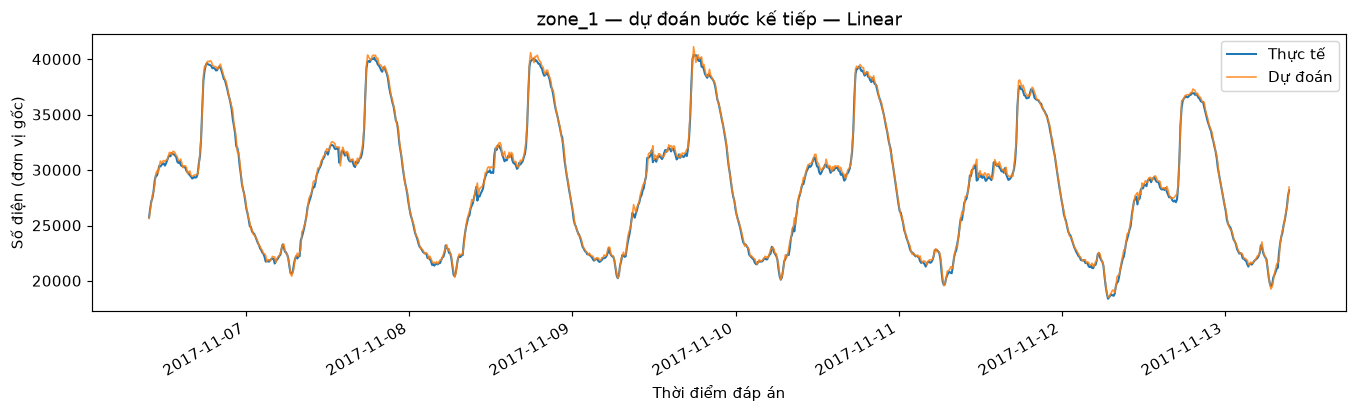

In [26]:
shown = timeline[timeline['Lúc đáp án'] < timeline['Lúc đáp án'].iloc[0] + pd.Timedelta(days=7)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(shown['Lúc đáp án'], shown['Thực tế'], label='Thực tế', linewidth=1.4)
ax.plot(shown['Lúc đáp án'], shown['Dự đoán'], label='Dự đoán', linewidth=1.1, alpha=0.85)
ax.set(title=f'{plot_zone} — dự đoán bước kế tiếp — {best_name}', xlabel='Thời điểm đáp án', ylabel='Số điện (đơn vị gốc)')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('next_step_forecast.png', dpi=160)
plt.show()


## 13. Lưu kết quả
Các bảng CSV và ảnh được tạo lại khi chạy. Bảng optimization_progression.csv giữ kết quả từng bước; bảng all_experiment_results.csv giữ mọi cấu hình đã thử.
Kết luận dựa vào bảng chạy thật, kể cả bước không cải thiện. Thêm mô hình, tham số hoặc tháng không bảo đảm tốt hơn.


In [27]:
feature_ablation.to_csv('feature_ablation_comparison.csv')
delta_results.to_csv('delta_target_comparison.csv')
seasonality.to_csv('seasonality_comparison.csv', index=False)
validation_results.to_csv('validation_model_comparison.csv')
tuning_results.to_csv('tuning_comparison.csv', index=False)
train_test_results.to_csv('train_test_model_comparison.csv')
weekly_mae.to_csv('mae_by_week.csv')
monthly_mae.to_csv('mae_by_month.csv')
forecast_table = pd.DataFrame({'origin': test_origin.to_numpy(), 'target_time': test_target_time.to_numpy()})
for i, zone in enumerate(zones):
    forecast_table[zone + '_actual'] = y_test[zone].to_numpy()
    forecast_table[zone + '_predicted'] = best_test_prediction[:, i]
    forecast_table[zone + '_absolute_error'] = np.abs(y_test[zone].to_numpy() - best_test_prediction[:, i])
forecast_table.to_csv('next_step_predictions.csv', index=False)
print('Chu kỳ được chọn:', selected_group, '| Mô hình được chọn trên validation:', best_name)
print('MAE validation:', validation_results.loc[best_name, 'MAE'])
print('MAE test:', train_test_results.loc[best_name, 'Test MAE'])
all_results.to_csv('all_experiment_results.csv')
progress_table.to_csv('optimization_progression.csv', index=False)
zone_mae.to_csv('test_mae_by_zone.csv')
print('Đã lưu 12 bảng CSV và ảnh next_step_forecast.png.')


Chu kỳ được chọn: + Tuần | Mô hình được chọn trên validation: Linear
MAE validation: 163.7002081309757
MAE test: 173.53089669485598
Đã lưu 12 bảng CSV và ảnh next_step_forecast.png.


### Phạm vi, việc chưa thử và nguồn
Dữ liệu chỉ có Tetouan năm 2017. Kết quả không tự động áp dụng cho doanh nghiệp hoặc năm khác.
Test đã được chấm ở các phiên trước và tiếp tục được đối chiếu sau từng bước theo yêu cầu nhóm. Không gọi đây là kiểm chứng trên tập hoàn toàn mới; muốn kiểm chứng độc lập cần dữ liệu tương lai mới.
Các thử nghiệm chọn bằng train/CV/validation. Bảng test có thể giúp mô tả kết quả, không được dùng để chọn các lượt thử tiếp theo.
Chưa thử cây riêng từng khu vực. Linear hiện tại đã có bộ hệ số riêng cho ba đáp án; tách ba lệnh fit với cùng X không phải một cải tiến mới.
Chưa tách thử nghiệm riêng bỏ/giữ sin/cos, nên không quy phần cải thiện chung cho riêng cách mã hóa này.
MLP theo chương 11, metrics chương 13, PCA chương 14. Không ép phân cụm vào bài hồi quy.
Cần đối chiếu yêu cầu chia dữ liệu/ngôn ngữ/template môn học trước khi nộp. Bản này dùng tiếng Việt để nhóm học hiểu.

Nguồn: [UCI Tetouan](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city), [yêu cầu môn học](https://docs.google.com/spreadsheets/d/17AhxqqU-uAUvH9RTIqbgO1w13_obfjTln45ukoH7SmM/edit), [GitHub nhóm](https://github.com/huy1907ddddddd/DS66B_group_14).
